# Capstone — Can prior search signals help editors choose what to review first?

**Author:** Harsha Vardhan  
**Lane:** Refresh / Content Opportunity Scoring  
**Repo:** [mhv-codes/flyrank-ml-internship](https://github.com/mhv-codes/flyrank-ml-internship)  
**Open in Colab:** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mhv-codes/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This notebook trains and evaluates one simple ranking model against the Week 4 prior-impressions rule. It uses only the committed, anonymized 30,000-row starter slice; it does **not** claim to rerun on the full 79-million-row warehouse. The model is decision support for a human editor, not an automatic refresh instruction.

## 1. Question

**Question:** Within this fixed starter snapshot, does logistic regression using prior impressions, prior clicks, and age at cutoff rank pages with a later 20%+ impression decline ahead of a simple prior-impressions ranking on the same held-out clients?

**Decision supported:** Which eligible pages should an editor inspect first when review capacity is limited? A false positive spends review time; a false negative leaves a possible issue unexamined. The score does not say that editing will recover traffic.

## 2. Data

The input is `data/raw/content_refresh_anonymized.csv`, a 30,000-row, 44-column starter extract from the repo. The analysis reads only the columns needed for the prior and outcome windows, cutoff age, type, and pseudonymous grouping keys. It filters to content at least 30 days old at cutoff with at least 500 prior-window impressions, producing the same eligible pool as the preceding playbook. The label uses the following 30-day impressions; no row-level identifiers or outcomes are exported. IDs are used only for grouped splitting and stable tie-breaking, never as features.

The exact input commit and SHA-256 are checked below. The comparison windows are the dataset's adjacent `prev_30d` and `last_30d` fields; no calendar-date range is inferred from this static slice.

## 3. Methodology

The target is 1 when `impressions_last_30d < 0.8 × impressions_prev_30d`. Features are `impressions_prev_30d`, `clicks_prev_30d`, and `age_at_cutoff` (content age shifted back 30 days). The model is `log1p` + training-only standardization + regularized logistic regression (`max_iter=1000`, seed 42). The baseline ranks by prior-window impressions. Both methods share one seeded 75/25 `GroupShuffleSplit` by `client_id`; 21 clients train and 7 clients are held out. Precision@10 and @50, average precision and ROC AUC are computed on the same 783 holdout rows.

Leakage checks keep outcome-window impressions, trend labels, trend percentages and product flags out of the feature matrix. The group-overlap assertion must be zero. This client holdout checks transfer across clients in this one snapshot; it is not a future-time test.

In [1]:
from pathlib import Path
from hashlib import sha256
from urllib.request import urlopen
import json
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

SEED = 42
RELATIVE_INPUT = Path("data/raw/content_refresh_anonymized.csv")
EXPECTED_SHA256 = "c43bdac4eccfa17fcd8a33974fe36f2c998c03a3ae3af8d80cf712abab5d6396"
DATA_COMMIT = "48d0dac47169e9f14b106037938d414b16529aaf"
here = Path.cwd()
repo_root = next((p for p in (here, *here.parents) if (p / RELATIVE_INPUT).is_file()), None)
if repo_root is None:
    # Colab fallback: obtain the exact committed public starter-data release.
    repo_root = here
    data_url = ("https://raw.githubusercontent.com/mhv-codes/flyrank-ml-internship/"
                f"{DATA_COMMIT}/{RELATIVE_INPUT.as_posix()}")
    with urlopen(data_url, timeout=60) as response:
        starter_csv = response.read()
    if sha256(starter_csv).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Downloaded starter data does not match the verified release.")
    data_path = repo_root / RELATIVE_INPUT
    data_path.parent.mkdir(parents=True, exist_ok=True)
    data_path.write_bytes(starter_csv)
else:
    data_path = repo_root / RELATIVE_INPUT
    if sha256(data_path.read_bytes()).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Local starter data does not match the verified release.")

keys = ["client_id", "content_id"]
feature_columns = ["impressions_prev_30d", "clicks_prev_30d", "age_at_cutoff"]
columns = keys + ["content_age_days", "content_type", "impressions_prev_30d",
                  "clicks_prev_30d", "impressions_last_30d"]
data = pd.read_csv(data_path, usecols=columns)
assert len(data) == 30_000 and not data.duplicated(keys).any()
data["age_at_cutoff"] = data["content_age_days"] - 30
eligible = data.loc[data.age_at_cutoff.ge(30) & data.impressions_prev_30d.ge(500)].copy()
assert eligible[feature_columns + ["impressions_last_30d"]].notna().all().all()
assert eligible[feature_columns].ge(0).all().all()
eligible["decline"] = (5 * eligible.impressions_last_30d < 4 * eligible.impressions_prev_30d).astype(int)
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
                           .split(eligible, groups=eligible.client_id))
train, test = eligible.iloc[train_idx].copy(), eligible.iloc[test_idx].copy()
model = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                      LogisticRegression(max_iter=1000, random_state=SEED))
model.fit(train[feature_columns], train.decline)
test["risk_probability"] = model.predict_proba(test[feature_columns])[:, 1]

def precision_at(frame, score, k):
    ranked = frame.sort_values([score, *keys], ascending=[False, True, True])
    return float(ranked.head(k).decline.mean())

baseline = test.assign(baseline_score=test.impressions_prev_30d)
metrics = {
    "dataset_sha256": EXPECTED_SHA256,
    "data_commit": DATA_COMMIT,
    "seed": SEED,
    "snapshot_rows": int(len(data)),
    "eligible_rows": int(len(eligible)),
    "train_rows": int(len(train)),
    "test_rows": int(len(test)),
    "train_clients": int(train.client_id.nunique()),
    "heldout_clients": int(test.client_id.nunique()),
    "client_overlap": int(len(set(train.client_id) & set(test.client_id))),
    "heldout_decline_base_rate": float(test.decline.mean()),
    "features": feature_columns,
    "label_definition": "impressions_last_30d < 0.8 * impressions_prev_30d",
    "baseline": {
        "precision_at_10": precision_at(baseline, "baseline_score", 10),
        "precision_at_50": precision_at(baseline, "baseline_score", 50),
        "average_precision": float(average_precision_score(test.decline, baseline.baseline_score)),
        "roc_auc": float(roc_auc_score(test.decline, baseline.baseline_score)),
    },
    "logistic_regression": {
        "precision_at_10": precision_at(test, "risk_probability", 10),
        "precision_at_50": precision_at(test, "risk_probability", 50),
        "average_precision": float(average_precision_score(test.decline, test.risk_probability)),
        "roc_auc": float(roc_auc_score(test.decline, test.risk_probability)),
    },
    "software": {"pandas": pd.__version__, "scikit_learn": sklearn.__version__},
}
assert metrics["client_overlap"] == 0 and metrics["heldout_clients"] == 7
assert set(feature_columns).isdisjoint({"decline", "trend_pct", "trend_direction", "is_declining_label"})
print(f"Snapshot rows: {len(data):,}; eligible: {len(eligible):,}; train: {len(train):,}; test: {len(test):,} across {test.client_id.nunique()} held-out clients.")
print(f"Client overlap: {metrics['client_overlap']}; holdout decline base rate: {metrics['heldout_decline_base_rate']:.3f}.")
print("Feature leakage and dataset identity checks passed.")

Snapshot rows: 30,000; eligible: 11,119; train: 10,336; test: 783 across 7 held-out clients.
Client overlap: 0; holdout decline base rate: 0.911.
Feature leakage and dataset identity checks passed.


## 4. Results (same test split)

The held-out decline base rate is included beside ranking metrics because precision is easier when positive labels are common. All values below are recomputed by this notebook from the pinned input.

In [2]:
results = pd.DataFrame([
    {"method": "Prior-impressions rule", **metrics["baseline"]},
    {"method": "Logistic regression", **metrics["logistic_regression"]},
]).set_index("method")
print(results.round(4).to_string())
assert results.loc["Logistic regression", "precision_at_50"] > results.loc["Prior-impressions rule", "precision_at_50"]

                        precision_at_10  precision_at_50  average_precision  roc_auc
method                                                                              
Prior-impressions rule              0.8             0.92             0.9309   0.6205
Logistic regression                 1.0             0.98             0.9483   0.6463


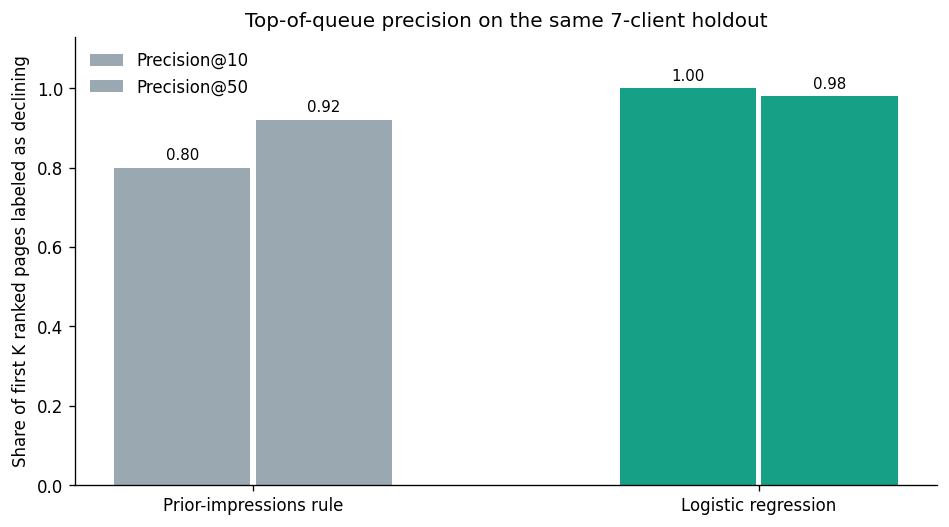

In [3]:
import matplotlib.pyplot as plt
from pathlib import Path

figure_dir = repo_root / "work" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
methods = ["Prior-impressions rule", "Logistic regression"]
colors = ["#9aa8b2", "#16a085"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, metric in enumerate(["precision_at_10", "precision_at_50"]):
    vals = [metrics["baseline"][metric], metrics["logistic_regression"][metric]]
    xs = np.arange(2) + (i - .5) * .28
    bars = ax.bar(xs, vals, width=.27, label=metric.replace("precision_at_", "Precision@"), color=colors)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(np.arange(2), methods)
ax.set_ylim(0, 1.13)
ax.set_ylabel("Share of first K ranked pages labeled as declining")
ax.set_title("Top-of-queue precision on the same 7-client holdout")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "capstone_precision.svg", format="svg", bbox_inches="tight")
plt.show()

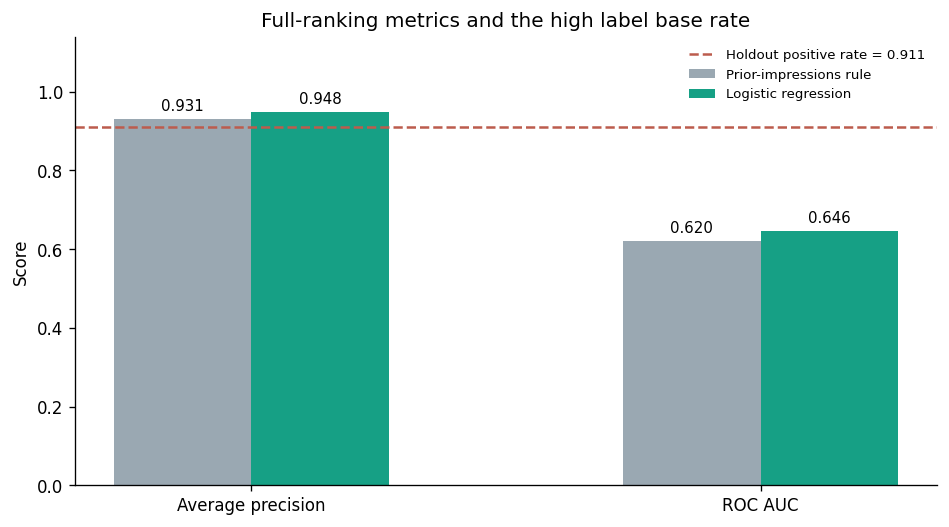

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
metrics_to_plot = ["average_precision", "roc_auc"]
x = np.arange(2)
width = .27
for j, (method, values, color) in enumerate([
    ("Prior-impressions rule", metrics["baseline"], colors[0]),
    ("Logistic regression", metrics["logistic_regression"], colors[1]),
]):
    vals = [values[m] for m in metrics_to_plot]
    bars = ax.bar(x + (j-.5)*width, vals, width=width, label=method, color=color)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axhline(metrics["heldout_decline_base_rate"], color="#bc5c4d", linestyle="--", linewidth=1.5,
           label=f"Holdout positive rate = {metrics['heldout_decline_base_rate']:.3f}")
ax.set_xticks(x, ["Average precision", "ROC AUC"])
ax.set_ylim(0, 1.14)
ax.set_ylabel("Score")
ax.set_title("Full-ranking metrics and the high label base rate")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "capstone_ranking_quality.svg", format="svg", bbox_inches="tight")
plt.show()

## 5. Errors and interpretation

At a separate 0.50 classification threshold (not the ranking decision), the notebook counts false positives and false negatives and summarizes their aggregate age and prior-impression profiles. These summaries contain no page IDs. Logistic coefficients are standardized log-feature associations; correlated impressions and clicks mean their signs should be read jointly, not as causes.

In [5]:
test["predicted_decline_at_0_5"] = test.risk_probability.ge(.5)
error_masks = {
    "False negative": test.decline.eq(1) & ~test.predicted_decline_at_0_5,
    "False positive": test.decline.eq(0) & test.predicted_decline_at_0_5,
    "True positive": test.decline.eq(1) & test.predicted_decline_at_0_5,
    "True negative": test.decline.eq(0) & ~test.predicted_decline_at_0_5,
}
error_rows = []
for name, mask in error_masks.items():
    group = test.loc[mask]
    error_rows.append({"case": name, "n": len(group),
                       "mean_prior_impressions": group.impressions_prev_30d.mean(),
                       "mean_age_at_cutoff_days": group.age_at_cutoff.mean()})
error_summary = pd.DataFrame(error_rows).set_index("case")
print("Classification threshold is illustrative; ranking metrics remain the primary evaluation.")
print(error_summary.round(1).to_string())
coef = model.named_steps["logisticregression"].coef_[0]
coef_summary = pd.DataFrame({"feature": feature_columns, "standardized_log_coefficient": coef})
print("\nStandardized log-feature coefficients (associations, not causal effects):")
print(coef_summary.round(3).to_string(index=False))

Classification threshold is illustrative; ranking metrics remain the primary evaluation.
                  n  mean_prior_impressions  mean_age_at_cutoff_days
case                                                                
False negative  185                  8454.7                    184.5
False positive   39                  2830.8                    259.7
True positive   528                  3819.5                    140.6
True negative    31                  7101.5                    304.9

Standardized log-feature coefficients (associations, not causal effects):
             feature  standardized_log_coefficient
impressions_prev_30d                         0.286
     clicks_prev_30d                        -0.716
       age_at_cutoff                        -0.319


**Error read:** the fixed holdout has many more declining than non-declining pages. At a 0.50 threshold, errors remain in both directions; the false-negative group is older and has more prior impressions on average than the false-positive group. The model therefore cannot replace a human check of current accuracy, intent, measurement changes, and page context. Precision@K is more aligned with the stated review-budget action than threshold accuracy.

## 6. Ranked recommendations

1. **Review the highest-risk eligible pages first**, within a capped editorial budget. The model modestly improves ranking over the prior-impressions baseline on this holdout; this is a prioritization result, not expected traffic recovery.
2. **Inspect the page and measurement context before proposing an edit.** Confirm the decline is not tracking loss, seasonality, or a changed reporting window; review source freshness and reader intent.
3. **Record the editor decision and evaluate later in time.** Keep, change, or reject the suggestion with a reason; compare an untouched future window before using the scores operationally.

Never automatically publish or rewrite content, alter indexing or canonical settings, delete pages, contact clients, allocate budget, or guarantee traffic or revenue.

## 7. Artifacts the paper embeds

The two charts below are generated from the run above and saved as public-safe SVGs under `work/figures/`. They contain only aggregate scores. The committed metrics JSON is a compact receipt; the ranked page queue remains uncommitted by repository policy.

In [6]:
metrics_path = repo_root / "work" / "outputs" / "capstone_metrics.json"
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(metrics, indent=2, sort_keys=True) + "\n", encoding="utf-8")
print(f"Wrote metrics receipt: {metrics_path.relative_to(repo_root)}")
print(f"Wrote aggregate charts: {figure_dir.relative_to(repo_root)}/capstone_precision.svg and capstone_ranking_quality.svg")
print("No row-level content IDs, client IDs, URLs, queries, or outcomes are exported.")

Wrote metrics receipt: work/outputs/capstone_metrics.json
Wrote aggregate charts: work/figures/capstone_precision.svg and capstone_ranking_quality.svg
No row-level content IDs, client IDs, URLs, queries, or outcomes are exported.


## 8. Limitations and reproducibility

This is one anonymized 30,000-row starter slice, one seed, one 7-client holdout, and one adjacent pair of 30-day windows. The test decline base rate (91.1%) is higher than the training rate noted in the Week 5 record. The model's top-50 gain is small in absolute terms: 49 of 50 versus 46 of 50, or three additional observed declines on this split. This is not a time-forward validation and cannot prove that a refresh causes recovery. The input metrics are aggregated; live URLs, raw queries, business priorities, seasonality, and editorial judgments are not represented.

From a fresh clone, run `python -m pip install -r requirements.txt`, then open this notebook in Colab and choose **Runtime → Run all** (or run it with Jupyter). The notebook downloads the exact public starter-data commit only when the local CSV is absent, checks its SHA-256, fixes seed 42, and writes the aggregate metrics and two SVG charts. The model comparison and baseline are recalculated from the same split each run.

## Research and design notes

Before drafting this page, I reviewed the FlyRank March 2026 SEO research report, the Scientific Reports paper-structure guidance, the NeurIPS reproducibility checklist, and Datawrapper's chart examples. I used a question-shaped title; put the five-sentence abstract first; made data windows, split, label, base rate, limitations, and rerun steps easy to find; and limited charts to one message each with a written takeaway. The FlyRank report analyzes a separate 341,701-piece portfolio and treats its ML pages as exploratory. This notebook instead evaluates the smaller, committed starter slice and does not transfer the broader report's aggregate claims to this model.

## ML-12 — Five-minute demo outline and shareable cuts

### 5-minute demonstration outline

- **0:00–0:40 — Question:** Show the research question and explain the editor's limited review budget.
- **0:40–1:35 — Data and label:** Show the pinned data hash, 30,000-row slice, eligibility filters, and two adjacent windows; explain that later-window impressions create the outcome only.
- **1:35–2:30 — Method:** Show the grouped client split and compare the logistic model with the prior-impressions rule on the same seven-client holdout.
- **2:30–3:30 — One chart:** Show top-10 and top-50 precision alongside the 91.1% holdout base rate; state the absolute top-50 difference is three rows.
- **3:30–4:20 — Honest result:** Show the aggregate threshold-error table and explain why ranking precision does not mean a refresh will recover traffic.
- **4:20–5:00 — Recommendation:** Close with human review first, an untouched future-time evaluation next, and no automatic publishing.

### Short methodology post

I compared a simple prior-impressions rule with logistic regression for ranking content pages that later showed a 20%+ impression decline. The model used only prior-window impressions and clicks plus content age at cutoff, and I held out whole clients to prevent client overlap. On this one seven-client holdout, precision@50 was 0.98 for the model versus 0.92 for the rule; the test set's decline base rate was 0.91, so the result is a modest directional ranking improvement, not evidence that a refresh causes traffic recovery. The score is a human-review queue, not an automatic edit instruction. [Notebook and methods](https://github.com/mhv-codes/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb).

### Employer-facing summary (three sentences)

I built a reproducible content-review ranking experiment comparing logistic regression with a prior-impressions rule. It used FlyRank's anonymized 30,000-row starter slice, with prior-window signals and a seven-client grouped holdout. The model ranked 49 observed declines in its top 50 versus 46 for the rule on that split; this supports a cautious review-priority experiment, not a causal claim about traffic lift.

## Acknowledgments & data credit

Built on the [FlyRank ML Internship dataset](https://flyrank.ai). The analysis uses the repository's anonymized starter extract; it does not publish client names, domains, URLs, raw queries, pseudonymous IDs, or row-level outcomes.

## Self-check

- [x] All paper sections have notebook backing and the core experiment runs from the pinned starter slice.
- [x] Baseline and model share the same client-group holdout; seed and dataset hash are fixed.
- [x] The held-out base rate, interpretation, error summary, limitations, charts, and recommendations are visible.
- [x] No future-window or label-derived fields are model inputs; no identifiers are exported.
- [ ] `submission/paper_url.txt` must be set to the exact URL after GitHub Pages is live and verified.
- [ ] After commit, run once in Google Colab from the repo badge and save the executed notebook if Colab confirms the same results.